Original Dataset:
   mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4        20.29         14.34          135.10     1297.0          0.10030   

   mean compactness  mean concavity  mean concave points  mean symmetry  \
0           0.27760          0.3001              0.14710         0.2419   
1           0.07864          0.0869              0.07017         0.1812   
2           0.15990          0.1974              0.12790         0.2069   
3           0.28390          0.2414              0.10520         0.2597   
4           0.13280          0.1980              0.10430         0.1809   

   mean fractal dimension  ...  worst texture  worst perimeter  worst area

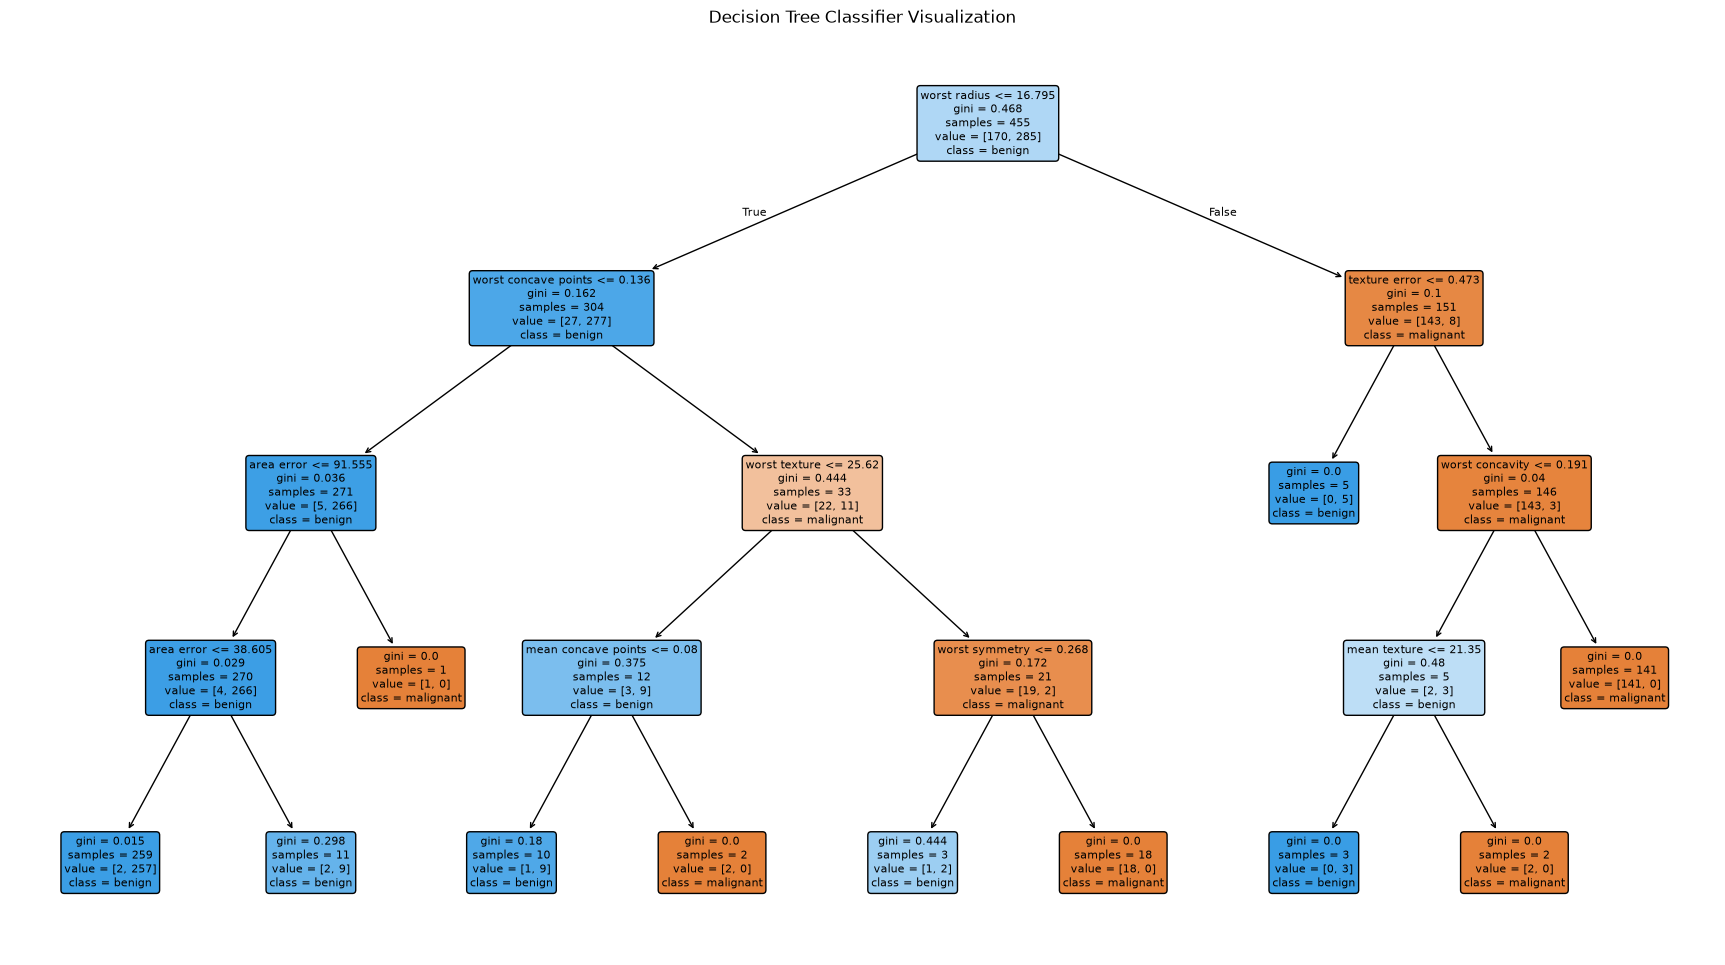


Confusion Matrix:
[[39  3]
 [ 4 68]]


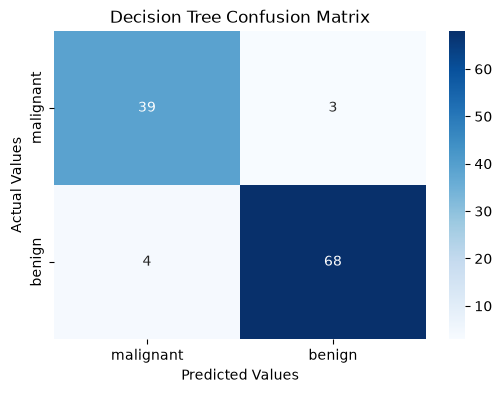


Accuracy: 0.9385964912280702
Precision: 0.9577464788732394
Recall: 0.9444444444444444
F1 Score: 0.951048951048951

Classification Report:
              precision    recall  f1-score   support

   malignant       0.91      0.93      0.92        42
      benign       0.96      0.94      0.95        72

    accuracy                           0.94       114
   macro avg       0.93      0.94      0.93       114
weighted avg       0.94      0.94      0.94       114


Feature Importance:
                 Feature  Importance
20          worst radius    0.733548
27  worst concave points    0.122028
11         texture error    0.045785
21         worst texture    0.032319
26       worst concavity    0.017161
7    mean concave points    0.013327
13            area error    0.012704
1           mean texture    0.011846
28        worst symmetry    0.011282
3              mean area    0.000000


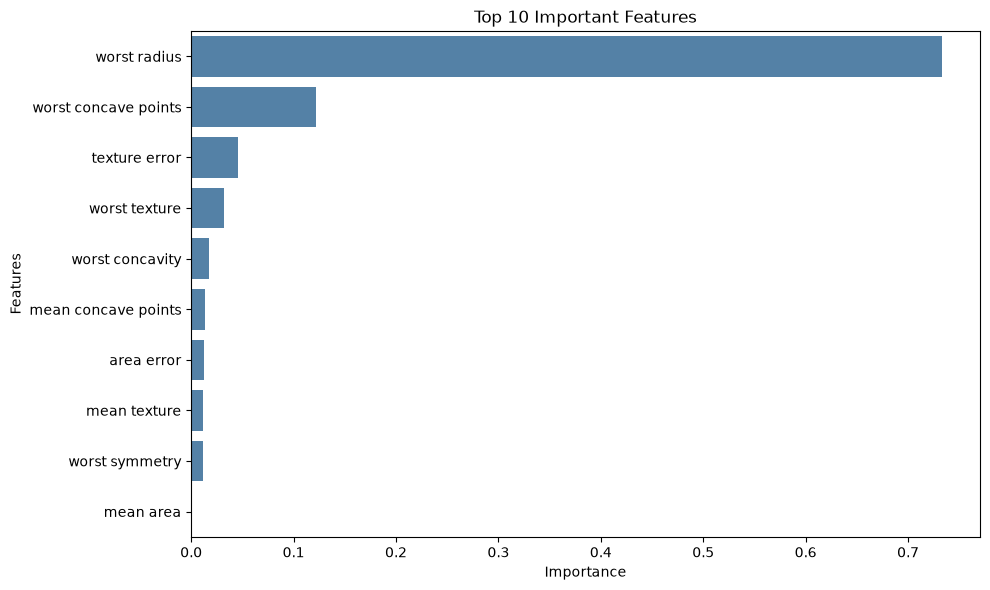


========== FINAL MODEL EVALUATION ==========
Accuracy : 93.86 %
Precision: 0.958
Recall   : 0.944
F1 Score : 0.951

Program Completed Successfully!


In [1]:

# =====================================================
# DECISION TREE CLASSIFIER
# BUILDING, VISUALIZATION AND EVALUATION
# REAL-WORLD DATASET
# =====================================================

# 1. IMPORT LIBRARIES

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree

from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)


# 2. LOAD REAL-WORLD DATASET

data = load_breast_cancer()

df = pd.DataFrame(
    data.data,
    columns=data.feature_names
)

df['Target'] = data.target

print("Original Dataset:")
print(df.head())

print("\nDataset Shape:")
print(df.shape)

print("\nDataset Information:")
print(df.info())

print("\nMissing Values:")
print(df.isnull().sum())


# 3. SEPARATE FEATURES AND TARGET

X = df.drop('Target', axis=1)

y = df['Target']

print("\nFeatures:")
print(X.head())

print("\nTarget:")
print(y.head())


# 4. SPLIT DATASET INTO TRAINING AND TESTING

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("\nTraining Data Shape:", X_train.shape)
print("Testing Data Shape:", X_test.shape)


# 5. BUILD DECISION TREE CLASSIFIER

model = DecisionTreeClassifier(
    criterion='gini',
    max_depth=4,
    random_state=42
)

model.fit(X_train, y_train)

print("\nDecision Tree Model Trained Successfully!")


# 6. MAKE PREDICTIONS

y_pred = model.predict(X_test)

print("\nActual Values:")
print(y_test.values)

print("\nPredicted Values:")
print(y_pred)


# 7. VISUALIZE DECISION TREE

plt.figure(figsize=(22, 12))

plot_tree(
    model,
    feature_names=data.feature_names,
    class_names=data.target_names,
    filled=True,
    rounded=True,
    fontsize=8
)

plt.title("Decision Tree Classifier Visualization")

plt.show()


# 8. CONFUSION MATRIX

cm = confusion_matrix(y_test, y_pred)

print("\nConfusion Matrix:")
print(cm)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=data.target_names,
    yticklabels=data.target_names
)

plt.xlabel("Predicted Values")
plt.ylabel("Actual Values")
plt.title("Decision Tree Confusion Matrix")

plt.show()


# 9. CALCULATE ACCURACY

accuracy = accuracy_score(y_test, y_pred)

print("\nAccuracy:", accuracy)


# 10. CALCULATE PRECISION

precision = precision_score(
    y_test,
    y_pred,
    zero_division=0
)

print("Precision:", precision)


# 11. CALCULATE RECALL

recall = recall_score(
    y_test,
    y_pred,
    zero_division=0
)

print("Recall:", recall)


# 12. CALCULATE F1 SCORE

f1 = f1_score(
    y_test,
    y_pred,
    zero_division=0
)

print("F1 Score:", f1)


# 13. CLASSIFICATION REPORT

print("\nClassification Report:")

print(
    classification_report(
        y_test,
        y_pred,
        target_names=data.target_names,
        zero_division=0
    )
)


# 14. FEATURE IMPORTANCE

feature_importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

print("\nFeature Importance:")
print(feature_importance.head(10))


# 15. VISUALIZE FEATURE IMPORTANCE

plt.figure(figsize=(10, 6))

sns.barplot(
    data=feature_importance.head(10),
    x='Importance',
    y='Feature',
    color='steelblue'
)

plt.title("Top 10 Important Features")
plt.xlabel("Importance")
plt.ylabel("Features")

plt.tight_layout()
plt.show()


# 16. FINAL MODEL EVALUATION

print("\n========== FINAL MODEL EVALUATION ==========")

print("Accuracy :", round(accuracy * 100, 2), "%")

print("Precision:", round(precision, 3))

print("Recall   :", round(recall, 3))

print("F1 Score :", round(f1, 3))

print("\nProgram Completed Successfully!")
